In [1]:
import random
import matplotlib.pyplot as plt

# Genetic Algorithm parameters
POPULATION_SIZE = 10
CHROMOSOME_LENGTH = 5
GENERATIONS = 20
MUTATION_RATE = 0.1
CROSSOVER_RATE = 0.8

# Function to optimize
def fitness(x):
    return x ** 2

print("Genetic Algorithm Parameters")
print("Population Size :", POPULATION_SIZE)
print("Chromosome Length:", CHROMOSOME_LENGTH)
print("Generations      :", GENERATIONS)
print("Mutation Rate    :", MUTATION_RATE)
print("Crossover Rate   :", CROSSOVER_RATE)

Genetic Algorithm Parameters
Population Size : 10
Chromosome Length: 5
Generations      : 20
Mutation Rate    : 0.1
Crossover Rate   : 0.8


In [2]:
def create_population():
    population = []

    for _ in range(POPULATION_SIZE):
        chromosome = [
            random.randint(0, 1)
            for _ in range(CHROMOSOME_LENGTH)
        ]
        population.append(chromosome)

    return population


def binary_to_decimal(chromosome):
    value = 0

    for bit in chromosome:
        value = value * 2 + bit

    return value


population = create_population()

print("Initial Population:")
for chromosome in population:
    x = binary_to_decimal(chromosome)
    print(chromosome, "x =", x, "Fitness =", fitness(x))

Initial Population:
[1, 0, 1, 0, 0] x = 20 Fitness = 400
[0, 0, 0, 0, 0] x = 0 Fitness = 0
[0, 0, 1, 1, 1] x = 7 Fitness = 49
[1, 1, 0, 1, 0] x = 26 Fitness = 676
[0, 1, 1, 1, 1] x = 15 Fitness = 225
[1, 1, 1, 0, 0] x = 28 Fitness = 784
[1, 0, 1, 1, 1] x = 23 Fitness = 529
[0, 0, 1, 1, 0] x = 6 Fitness = 36
[1, 1, 1, 1, 1] x = 31 Fitness = 961
[0, 0, 0, 0, 1] x = 1 Fitness = 1


In [3]:
def calculate_fitness(population):
    fitness_values = []

    for chromosome in population:
        x = binary_to_decimal(chromosome)
        fitness_values.append(fitness(x))

    return fitness_values


fitness_values = calculate_fitness(population)

print("Fitness Values:")

for i in range(len(population)):
    x = binary_to_decimal(population[i])
    print(
        "Chromosome:", population[i],
        "x =", x,
        "Fitness =", fitness_values[i]
    )

Fitness Values:
Chromosome: [1, 0, 1, 0, 0] x = 20 Fitness = 400
Chromosome: [0, 0, 0, 0, 0] x = 0 Fitness = 0
Chromosome: [0, 0, 1, 1, 1] x = 7 Fitness = 49
Chromosome: [1, 1, 0, 1, 0] x = 26 Fitness = 676
Chromosome: [0, 1, 1, 1, 1] x = 15 Fitness = 225
Chromosome: [1, 1, 1, 0, 0] x = 28 Fitness = 784
Chromosome: [1, 0, 1, 1, 1] x = 23 Fitness = 529
Chromosome: [0, 0, 1, 1, 0] x = 6 Fitness = 36
Chromosome: [1, 1, 1, 1, 1] x = 31 Fitness = 961
Chromosome: [0, 0, 0, 0, 1] x = 1 Fitness = 1


In [4]:
def selection(population):
    selected = []

    for _ in range(len(population)):
        # Tournament selection
        a = random.choice(population)
        b = random.choice(population)

        if fitness(binary_to_decimal(a)) > fitness(binary_to_decimal(b)):
            selected.append(a.copy())
        else:
            selected.append(b.copy())

    return selected


selected_population = selection(population)

print("Selected Population:")

for chromosome in selected_population:
    x = binary_to_decimal(chromosome)
    print(
        chromosome,
        "x =", x,
        "Fitness =", fitness(x)
    )

Selected Population:
[1, 0, 1, 1, 1] x = 23 Fitness = 529
[1, 1, 1, 1, 1] x = 31 Fitness = 961
[1, 1, 0, 1, 0] x = 26 Fitness = 676
[1, 1, 0, 1, 0] x = 26 Fitness = 676
[0, 0, 0, 0, 1] x = 1 Fitness = 1
[0, 0, 1, 1, 0] x = 6 Fitness = 36
[1, 0, 1, 0, 0] x = 20 Fitness = 400
[1, 0, 1, 1, 1] x = 23 Fitness = 529
[1, 1, 1, 1, 1] x = 31 Fitness = 961
[1, 1, 1, 0, 0] x = 28 Fitness = 784


In [5]:
def crossover(parent1, parent2):
    if random.random() < CROSSOVER_RATE:

        point = random.randint(
            1,
            CHROMOSOME_LENGTH - 1
        )

        child1 = (
            parent1[:point] +
            parent2[point:]
        )

        child2 = (
            parent2[:point] +
            parent1[point:]
        )

        return child1, child2

    return parent1.copy(), parent2.copy()


def create_children(selected_population):
    children = []

    for i in range(0, len(selected_population), 2):

        parent1 = selected_population[i]
        parent2 = selected_population[
            (i + 1) % len(selected_population)
        ]

        child1, child2 = crossover(
            parent1,
            parent2
        )

        children.append(child1)
        children.append(child2)

    return children[:POPULATION_SIZE]


children = create_children(selected_population)

print("Population After Crossover:")

for chromosome in children:
    x = binary_to_decimal(chromosome)
    print(
        chromosome,
        "x =", x,
        "Fitness =", fitness(x)
    )

Population After Crossover:
[1, 0, 1, 1, 1] x = 23 Fitness = 529
[1, 1, 1, 1, 1] x = 31 Fitness = 961
[1, 1, 0, 1, 0] x = 26 Fitness = 676
[1, 1, 0, 1, 0] x = 26 Fitness = 676
[0, 0, 0, 0, 0] x = 0 Fitness = 0
[0, 0, 1, 1, 1] x = 7 Fitness = 49
[1, 0, 1, 1, 1] x = 23 Fitness = 529
[1, 0, 1, 0, 0] x = 20 Fitness = 400
[1, 1, 1, 0, 0] x = 28 Fitness = 784
[1, 1, 1, 1, 1] x = 31 Fitness = 961


In [6]:
def mutation(chromosome):
    chromosome = chromosome.copy()

    for i in range(len(chromosome)):

        if random.random() < MUTATION_RATE:
            chromosome[i] = 1 - chromosome[i]

    return chromosome


def mutate_population(population):
    return [
        mutation(chromosome)
        for chromosome in population
    ]


population = mutate_population(children)

print("Population After Mutation:")

for chromosome in population:
    x = binary_to_decimal(chromosome)

    print(
        chromosome,
        "x =", x,
        "Fitness =", fitness(x)
    )

Population After Mutation:
[1, 0, 1, 1, 1] x = 23 Fitness = 529
[1, 1, 1, 0, 1] x = 29 Fitness = 841
[1, 1, 0, 1, 0] x = 26 Fitness = 676
[1, 1, 0, 1, 0] x = 26 Fitness = 676
[0, 0, 0, 0, 0] x = 0 Fitness = 0
[0, 0, 1, 0, 1] x = 5 Fitness = 25
[1, 0, 1, 1, 1] x = 23 Fitness = 529
[1, 0, 1, 0, 1] x = 21 Fitness = 441
[1, 1, 1, 1, 0] x = 30 Fitness = 900
[1, 1, 0, 1, 1] x = 27 Fitness = 729


In [7]:
best_solutions = []
best_fitness_values = []

# Reinitialize population
population = create_population()

for generation in range(GENERATIONS):

    fitness_values = calculate_fitness(population)

    best_index = fitness_values.index(
        max(fitness_values)
    )

    best_chromosome = population[best_index]
    best_x = binary_to_decimal(best_chromosome)
    best_fitness = fitness(best_x)

    best_solutions.append(best_x)
    best_fitness_values.append(best_fitness)

    print(
        "Generation:", generation + 1,
        "| Best x:", best_x,
        "| Best Fitness:", best_fitness
    )

    # Selection
    selected = selection(population)

    # Crossover
    children = create_children(selected)

    # Mutation
    population = mutate_population(children)


# Final best solution
final_index = best_fitness_values.index(
    max(best_fitness_values)
)

print("\n===================================")
print("FINAL RESULT")
print("===================================")
print("Best Solution x =", best_solutions[final_index])
print("Maximum Fitness =", best_fitness_values[final_index])

Generation: 1 | Best x: 31 | Best Fitness: 961
Generation: 2 | Best x: 29 | Best Fitness: 841
Generation: 3 | Best x: 30 | Best Fitness: 900
Generation: 4 | Best x: 30 | Best Fitness: 900
Generation: 5 | Best x: 31 | Best Fitness: 961
Generation: 6 | Best x: 31 | Best Fitness: 961
Generation: 7 | Best x: 31 | Best Fitness: 961
Generation: 8 | Best x: 31 | Best Fitness: 961
Generation: 9 | Best x: 31 | Best Fitness: 961
Generation: 10 | Best x: 31 | Best Fitness: 961
Generation: 11 | Best x: 31 | Best Fitness: 961
Generation: 12 | Best x: 31 | Best Fitness: 961
Generation: 13 | Best x: 31 | Best Fitness: 961
Generation: 14 | Best x: 31 | Best Fitness: 961
Generation: 15 | Best x: 31 | Best Fitness: 961
Generation: 16 | Best x: 29 | Best Fitness: 841
Generation: 17 | Best x: 31 | Best Fitness: 961
Generation: 18 | Best x: 31 | Best Fitness: 961
Generation: 19 | Best x: 31 | Best Fitness: 961
Generation: 20 | Best x: 31 | Best Fitness: 961

FINAL RESULT
Best Solution x = 31
Maximum Fitnes

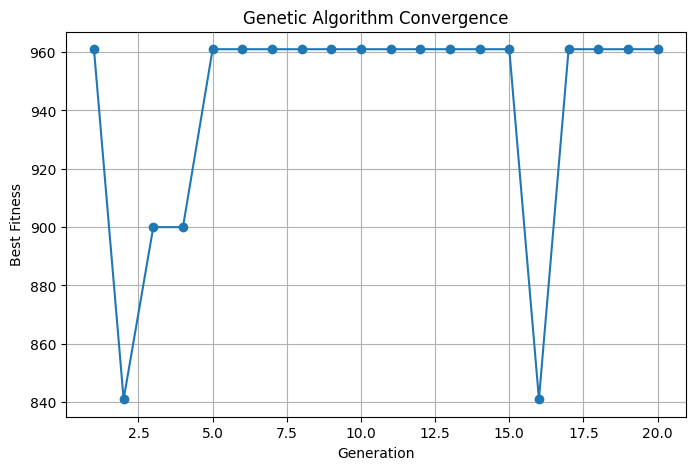


PARAMETER ANALYSIS

1. Population Size:
   A larger population provides more diversity and
   can improve solution quality, but increases computation.

2. Mutation Rate:
   A higher mutation rate increases exploration and
   helps avoid local optima. Too much mutation can
   slow convergence.

3. Crossover Rate:
   A higher crossover rate combines solutions more often
   and can improve convergence speed.

4. Number of Generations:
   More generations usually provide better solutions,
   but increase execution time.

5. Chromosome Length:
   A longer chromosome provides a larger search space
   and better precision, but requires more computation.

Conclusion:
The Genetic Algorithm gradually improves the fitness value
over generations. Proper selection of population size,
crossover rate, mutation rate, and number of generations
helps achieve faster convergence and better solutions.



In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, GENERATIONS + 1),
    best_fitness_values,
    marker='o'
)

plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.title("Genetic Algorithm Convergence")
plt.grid(True)

plt.show()


print("\n===================================")
print("PARAMETER ANALYSIS")
print("===================================")

print("""
1. Population Size:
   A larger population provides more diversity and
   can improve solution quality, but increases computation.

2. Mutation Rate:
   A higher mutation rate increases exploration and
   helps avoid local optima. Too much mutation can
   slow convergence.

3. Crossover Rate:
   A higher crossover rate combines solutions more often
   and can improve convergence speed.

4. Number of Generations:
   More generations usually provide better solutions,
   but increase execution time.

5. Chromosome Length:
   A longer chromosome provides a larger search space
   and better precision, but requires more computation.

Conclusion:
The Genetic Algorithm gradually improves the fitness value
over generations. Proper selection of population size,
crossover rate, mutation rate, and number of generations
helps achieve faster convergence and better solutions.
""")